# Experiment 5: Does the Model Hit the Requested Color Code?

Architects order paint by code (RAL, HEX). If a user asks *"paint the walls RAL 7016"*, the render must show **that** color, not just "some grey". Text-to-image models do not understand color codes: `#383E42` is just text to them.

**Task.** Repaint only the **walls** of each room in 5 RAL colors, and measure how close the result is to the requested color.

| Method | What it does |
|---|---|
| **A: Color name** | Prompt says the color in words: *"walls painted in anthracite grey"* |
| **B: HEX code** | Prompt says the code: *"walls painted in color #383E42"* |
| **C: Color-filled start** | The wall mask is first filled with the exact color; the model then adds texture and light (inpainting strength 0.6) |
| **D: C + color correction** | After C, the wall color is shifted in CIELAB to the target mean; light and shadow variation is kept |

All methods use the setup from Experiment 3: SegFormer mask, Canny ControlNet inpainting, original pixels pasted back outside the mask.

**Measured (on the wall mask, slightly shrunk to avoid edges)**
- **ΔE to target**: CIEDE2000 between the mean wall color and the target color. Below 2 is hard to see, below 5 is acceptable for a render.
- **Δab (hue/chroma error)**: the same, but ignoring lightness, because a wall in shadow is naturally darker than the paint chip.
- **ΔE outside**: color change outside the walls (should be close to 0).

*Note: RAL colors are defined for physical paint; the HEX values below are common sRGB approximations.*

## 1. Setup

In [ ]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload the same room images

In [3]:
from google.colab import files
uploaded = files.upload()
images = list(uploaded)
print(images)

Saving living-room.jpg to living-room.jpg
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
['living-room.jpg', 'open-plan.jpg', 'room.jpg']


## 4. Load the models

In [4]:
import cv2, numpy as np, pandas as pd
from PIL import Image
from diffusers import ControlNetModel, StableDiffusionControlNetInpaintPipeline
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
from skimage.color import rgb2lab, lab2rgb, deltaE_ciede2000

dtype = torch.float16
controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=dtype)
pipe = StableDiffusionControlNetInpaintPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", controlnet=controlnet,
    torch_dtype=dtype, safety_checker=None).to("cuda")
pipe.set_progress_bar_config(disable=True)

seg_name = "nvidia/segformer-b2-finetuned-ade-512-512"
seg_proc = SegformerImageProcessor.from_pretrained(seg_name)
seg_model = SegformerForSemanticSegmentation.from_pretrained(seg_name).to("cuda").eval()
WALL_ID = [i for i, l in seg_model.config.id2label.items() if l.split(",")[0].strip() == "wall"][0]
print("wall class id:", WALL_ID)

W, H = 768, 432
SEED, STEPS = 42, 25
negative = "blurry, distorted, low quality, deformed, text"

# common sRGB approximations of RAL colors
COLORS = {
    "RAL 7016 Anthracite grey": ("#383E42", "anthracite grey"),
    "RAL 5014 Pigeon blue":     ("#606E8C", "dusty pigeon blue"),
    "RAL 6021 Pale green":      ("#89AC76", "pale sage green"),
    "RAL 1015 Light ivory":     ("#E6D690", "light ivory"),
    "RAL 3012 Beige red":       ("#C1876B", "beige red terracotta"),
}

def hex_rgb(h):
    h = h.lstrip("#"); return np.array([int(h[i:i + 2], 16) for i in (0, 2, 4)], dtype=np.uint8)

def to_lab(rgb_uint8):
    return rgb2lab(rgb_uint8.reshape(-1, 1, 3) if rgb_uint8.ndim == 1 else rgb_uint8)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (7 outputs left out)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

wall class id: 0


## 5. Find the walls
The mask used for **painting** is grown a little (so the wall edges are repainted too). The mask used for **measuring** is shrunk a little (so mixed edge pixels do not count).

living-room.jpg walls = 26% of the image


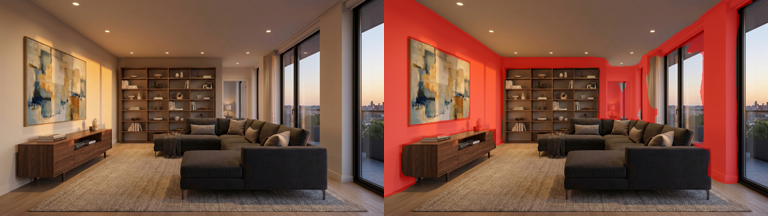

open-plan.jpg walls = 17% of the image


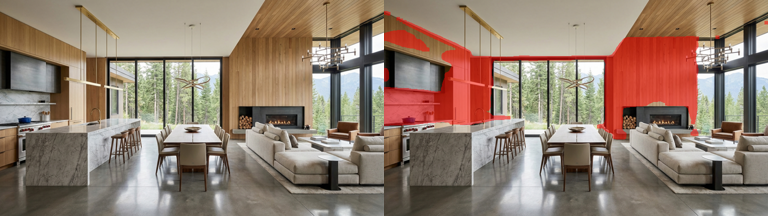

room.jpg walls = 17% of the image


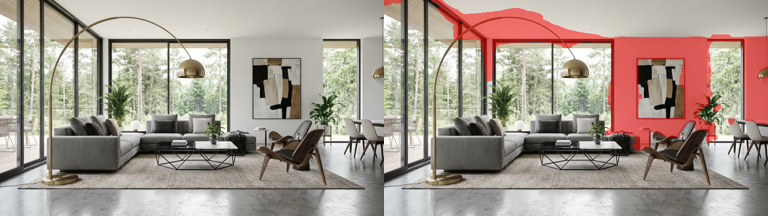

In [5]:
def load_room(name):
    return Image.open(name).convert("RGB").resize((W, H))

def canny_map(room):
    e = cv2.Canny(np.array(room), 100, 200)
    return Image.fromarray(np.stack([e] * 3, axis=-1))

def wall_masks(room):
    inputs = seg_proc(images=room, return_tensors="pt").to("cuda")
    with torch.no_grad():
        logits = seg_model(**inputs).logits
    logits = torch.nn.functional.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    wall = (logits.argmax(1)[0].cpu().numpy() == WALL_ID).astype(np.uint8)
    paint = cv2.dilate(wall, np.ones((7, 7), np.uint8)) * 255
    measure = cv2.erode(wall, np.ones((9, 9), np.uint8)) > 0
    return Image.fromarray(paint), measure

def show_row(imgs, scale=0.5):
    w, h = int(W * scale), int(H * scale)
    row = Image.new("RGB", (w * len(imgs), h), "white")
    for i, im in enumerate(imgs):
        row.paste(im.convert("RGB").resize((w, h)), (i * w, 0))
    display(row); return row

rooms, masks = {}, {}
for name in images:
    rooms[name] = load_room(name)
    masks[name] = wall_masks(rooms[name])
    red = np.array(rooms[name]).copy(); m = np.array(masks[name][0]) > 0
    red[m] = (0.5 * red[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    print(name, f"walls = {m.mean():.0%} of the image")
    show_row([rooms[name], Image.fromarray(red)])

**Check the masks.** If a room has very little visible wall (under about 10%), its numbers will be less reliable.

## 6. The four methods
- **A / B** repaint the wall mask from scratch (strength 1.0), only the prompt differs.
- **C** fills the wall mask with the exact color first, then lets the model add texture and light (strength 0.6).
- **D** shifts the wall pixels of C in CIELAB so their **mean** matches the target. Each pixel keeps its difference from the mean, so shading and texture stay.

In [6]:
def inpaint(room, mask, prompt, init=None, strength=1.0):
    raw = pipe(prompt, negative_prompt=negative, image=init if init is not None else room, mask_image=mask,
               control_image=canny_map(room), width=W, height=H, strength=strength,
               num_inference_steps=STEPS, generator=torch.manual_seed(SEED)).images[0]
    soft = pipe.mask_processor.blur(mask, blur_factor=4)
    return pipe.image_processor.apply_overlay(soft, room, raw)     # original pixels outside the walls

def fill_color(room, mask, hex_code):
    arr = np.array(room).copy(); arr[np.array(mask) > 0] = hex_rgb(hex_code)
    return Image.fromarray(arr)

def correct_color(img, mask, hex_code):
    m = np.array(mask) > 0
    target = to_lab(hex_rgb(hex_code))[0, 0]
    out = np.array(img)
    for _ in range(3):                                          # repeat: clipping to valid RGB moves the mean a little
        lab = rgb2lab(out)
        lab[m] = lab[m] - lab[m].mean(0) + target               # move the mean, keep the variation
        lab[..., 0] = np.clip(lab[..., 0], 0, 100)
        out = (np.clip(lab2rgb(lab), 0, 1) * 255).round().astype(np.uint8)
    soft = np.array(pipe.mask_processor.blur(mask, blur_factor=4)).astype(np.float32)[..., None] / 255
    return Image.fromarray((soft * out + (1 - soft) * np.array(img)).astype(np.uint8))

results = {}
for n, name in enumerate(images, start=1):
    room = rooms[name]; paint, _ = masks[name]
    for cname, (hex_code, words) in COLORS.items():
        a = inpaint(room, paint, f"photorealistic interior, walls painted in {words} color, natural light")
        b = inpaint(room, paint, f"photorealistic interior, walls painted in color {hex_code}, natural light")
        c = inpaint(room, paint, "photorealistic interior, painted walls, natural light",
                    init=fill_color(room, paint, hex_code), strength=0.6)
        d = correct_color(c, paint, hex_code)
        results[(name, cname)] = {"A: color name": a, "B: HEX code": b, "C: color-filled start": c, "D: C + correction": d}
    print(f"room {n} done")

room 1 done
room 2 done
room 3 done


## 7. Look at the results
Per room and color: **target swatch | original | A | B | C | D**.

room 1 | RAL 7016 Anthracite grey (#383E42): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


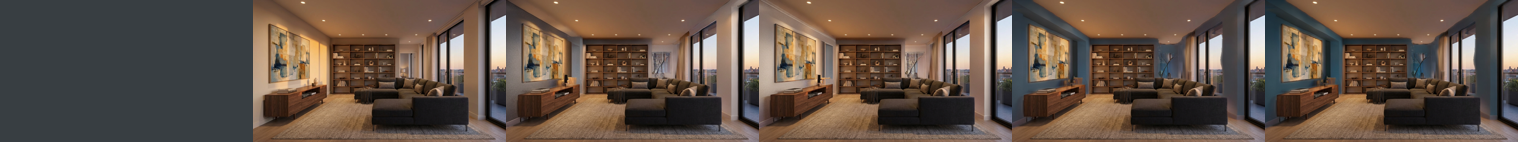

room 1 | RAL 5014 Pigeon blue (#606E8C): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


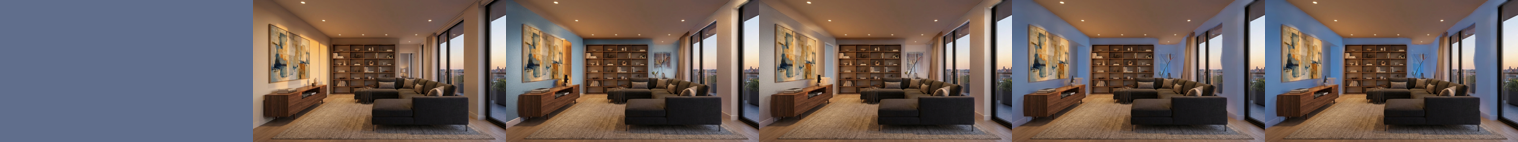

room 1 | RAL 6021 Pale green (#89AC76): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


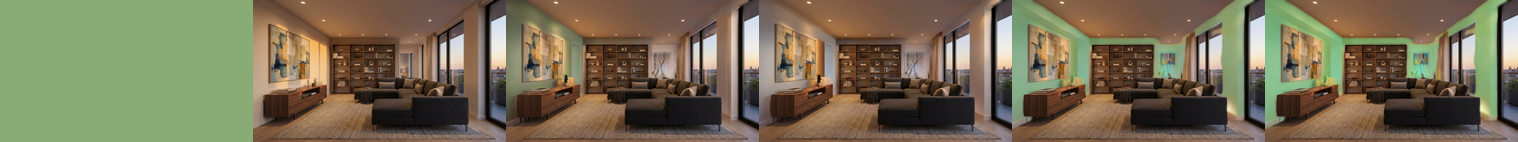

room 1 | RAL 1015 Light ivory (#E6D690): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


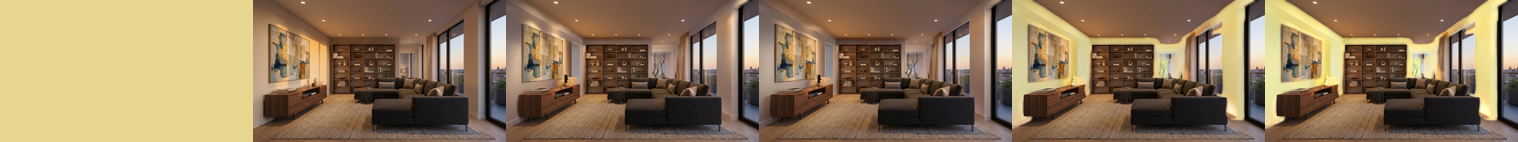

room 1 | RAL 3012 Beige red (#C1876B): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


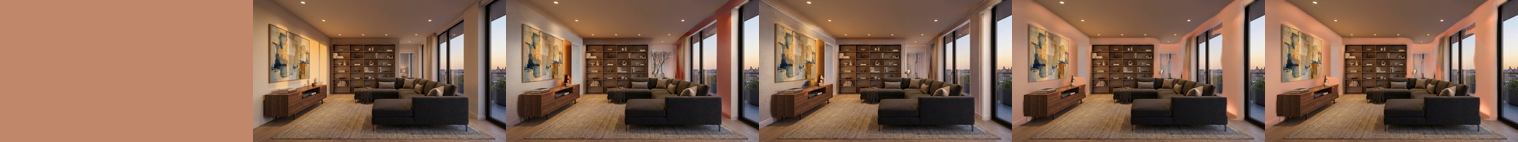

room 2 | RAL 7016 Anthracite grey (#383E42): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


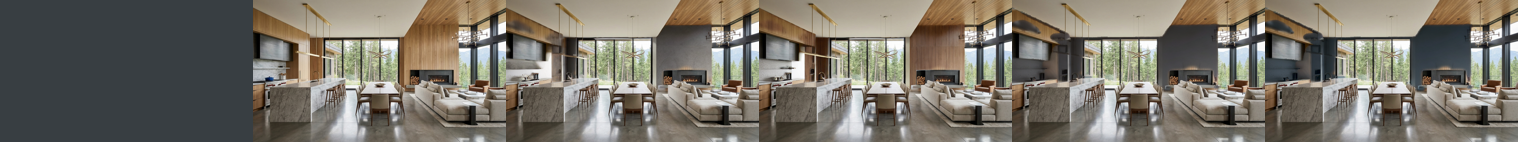

room 2 | RAL 5014 Pigeon blue (#606E8C): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


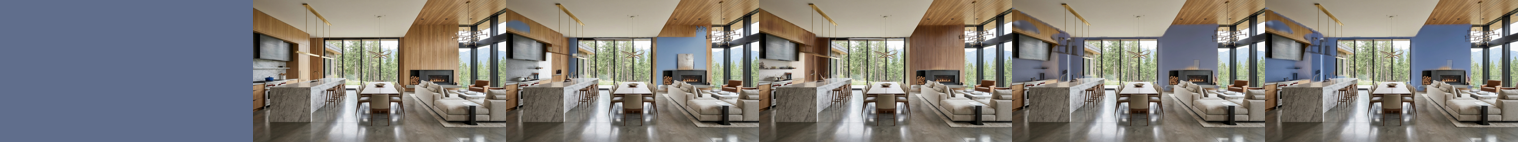

room 2 | RAL 6021 Pale green (#89AC76): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


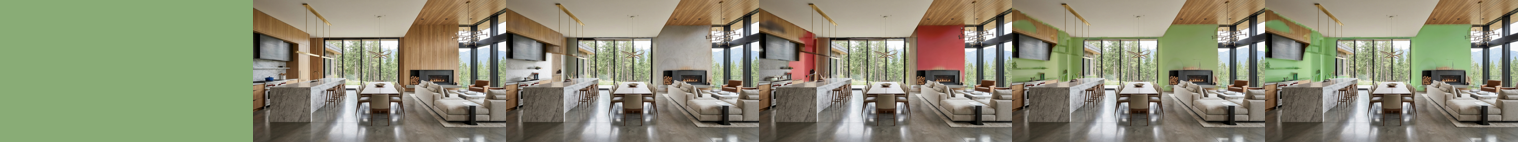

room 2 | RAL 1015 Light ivory (#E6D690): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


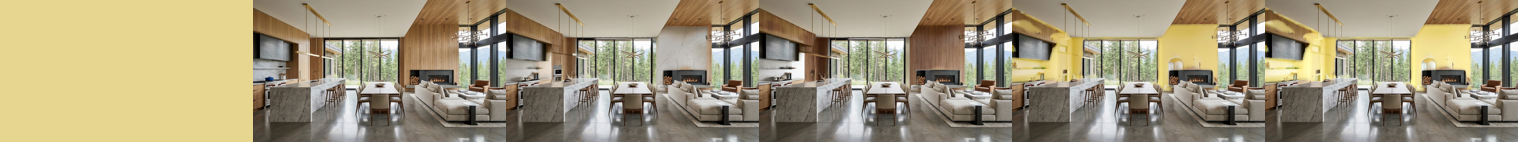

room 2 | RAL 3012 Beige red (#C1876B): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


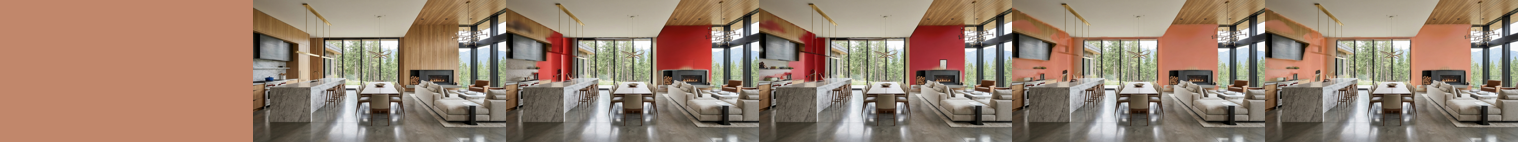

room 3 | RAL 7016 Anthracite grey (#383E42): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


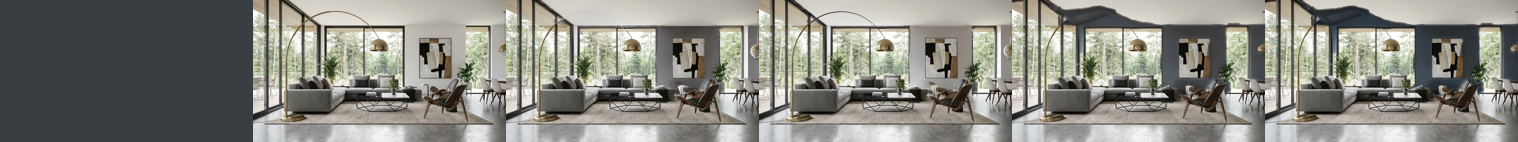

room 3 | RAL 5014 Pigeon blue (#606E8C): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


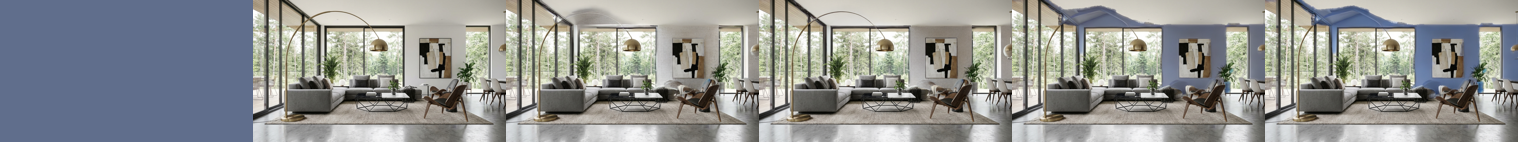

room 3 | RAL 6021 Pale green (#89AC76): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


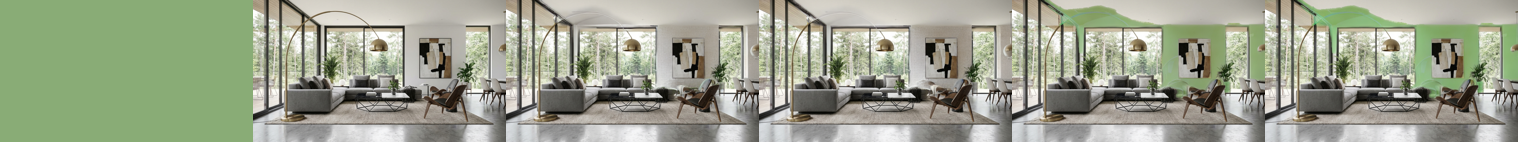

room 3 | RAL 1015 Light ivory (#E6D690): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


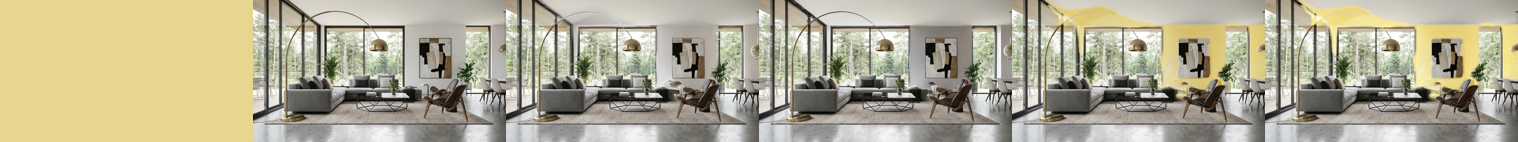

room 3 | RAL 3012 Beige red (#C1876B): swatch | original | A: color name | B: HEX code | C: color-filled start | D: C + correction


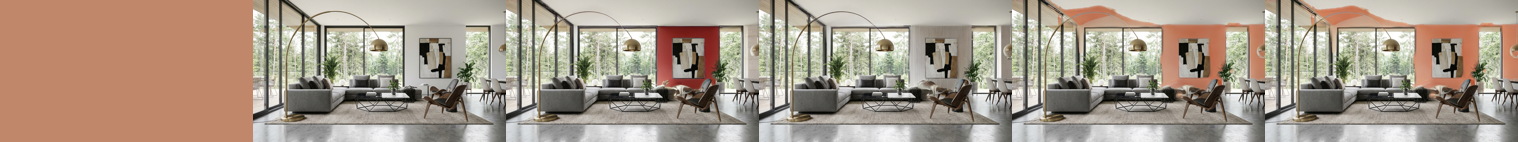

In [7]:
METHODS = ["A: color name", "B: HEX code", "C: color-filled start", "D: C + correction"]
def swatch(hex_code):
    return Image.new("RGB", (W, H), tuple(int(v) for v in hex_rgb(hex_code)))

for n, name in enumerate(images, start=1):
    for k, (cname, (hex_code, _)) in enumerate(COLORS.items(), start=1):
        print(f"room {n} | {cname} ({hex_code}): swatch | original | " + " | ".join(METHODS))
        row = show_row([swatch(hex_code), rooms[name]] + [results[(name, cname)][m] for m in METHODS], scale=0.33)
        row.save(f"exp5_room{n}_color{k}.jpg", quality=90)

## 8. Measure color accuracy

In [8]:
rows = []
for name in images:
    orig = np.array(rooms[name]); paint, measure = masks[name]
    outside = np.array(paint) == 0
    for cname, (hex_code, _) in COLORS.items():
        target = to_lab(hex_rgb(hex_code))[0, 0]
        for m in METHODS:
            img = np.array(results[(name, cname)][m])
            lab = rgb2lab(img)
            mean_lab = lab[measure].mean(0)
            rows.append({
                "room": images.index(name) + 1, "color": cname, "method": m,
                "ΔE to target ↓": float(deltaE_ciede2000(mean_lab[None, None], target[None, None])[0, 0]),
                "Δab hue/chroma ↓": float(np.linalg.norm(mean_lab[1:] - target[1:])),
                "ΔE outside ↓": float(deltaE_ciede2000(rgb2lab(orig), lab)[outside].mean()),
            })

df = pd.DataFrame(rows)
summary = df.groupby("method")[["ΔE to target ↓", "Δab hue/chroma ↓", "ΔE outside ↓"]].mean().reindex(METHODS)
summary["hit rate (ΔE < 5)"] = df.assign(hit=df["ΔE to target ↓"] < 5).groupby("method")["hit"].mean().reindex(METHODS)
display(summary.round(2))
display(df.pivot_table(index="color", columns="method", values="ΔE to target ↓").reindex(columns=METHODS).round(1))

,ΔE to target ↓,Δab hue/chroma ↓,ΔE outside ↓,hit rate (ΔE < 5)
method,,,,
A: color name,19.93,19.79,0.17,0.0
B: HEX code,26.44,25.20,0.17,0.0
C: color-filled start,3.86,4.58,0.17,0.8
D: C + correction,2.07,2.59,0.17,1.0


method,A: color name,B: HEX code,C: color-filled start,D: C + correction
color,,,,
RAL 1015 Light ivory,23.1,29.4,3.5,2.4
RAL 3012 Beige red,14.3,17.1,3.2,1.8
RAL 5014 Pigeon blue,20.6,24.0,4.6,1.9
RAL 6021 Pale green,20.4,30.4,4.3,2.0
RAL 7016 Anthracite grey,21.2,31.2,3.7,2.2


## 9. Chart

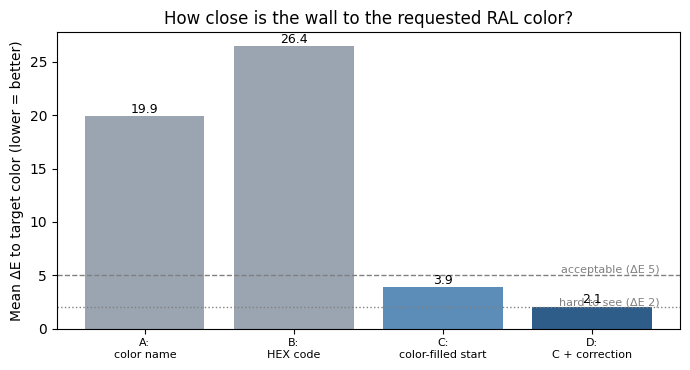

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.8))
vals = summary["ΔE to target ↓"]
ax.bar(range(len(vals)), vals, color=["#9aa5b1", "#9aa5b1", "#5b8db8", "#2f5d8a"])
ax.axhline(5, ls="--", c="grey", lw=1); ax.text(3.45, 5.2, "acceptable (ΔE 5)", ha="right", fontsize=8, color="grey")
ax.axhline(2, ls=":", c="grey", lw=1); ax.text(3.45, 2.2, "hard to see (ΔE 2)", ha="right", fontsize=8, color="grey")
ax.set_xticks(range(len(vals))); ax.set_xticklabels([m.replace(": ", ":\n") for m in vals.index], fontsize=8)
ax.set_ylabel("Mean ΔE to target color (lower = better)")
ax.set_title("How close is the wall to the requested RAL color?")
for i, v in enumerate(vals): ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("exp5_color_accuracy.png", dpi=150); plt.show()

**What I saw**

* **A (color name):** the model changes the wall color, but not to the requested one (mean ΔE 19.9, no color within ΔE 5). It often repaints only part of the wall, and "beige red terracotta" became a saturated red patch.
* **B (HEX code):** the worst method (mean ΔE 26.4). The walls mostly keep their original color, and in one room a green code (#89AC76) produced red patches. The model reads the HEX code as text, not as a color.
* **C (color-filled start):** filling the walls with the exact color first and letting the model add light and texture brings the wall close to the target (mean ΔE 3.9, 12 of 15 within ΔE 5). All 3 misses were in the open-plan room, where the wall mask also covered wood paneling and parts of the ceiling.
* **D (C + correction):** shifting the mean wall color to the target in CIELAB brings every case under ΔE 5 (mean ΔE 2.1, 15 of 15), close to the level where people can hardly see a difference (ΔE 2).

**Result.** Text alone cannot deliver a paint code: a color name gets the direction only roughly, and a HEX code is ignored. The color has to be given to the model as pixels (C), and a simple color correction after generation (D) closes the remaining gap. Outside the walls nothing changed for any method (ΔE 0.17), because the original pixels are kept outside the mask.

**Limits.** RAL→sRGB values are approximations, and a real wall under daylight is not the same as a paint chip, so ΔE includes lighting; Δab removes lightness but not color casts from light. Three rooms, one seed. The metric compares the **mean** wall color with the target, and method D moves exactly this mean, so its low ΔE is partly guaranteed by design; it shows that a simple post-correction is enough to hit the code, not that the result looks more realistic. Very uneven light can still leave parts of the wall off-target, and where the wall mask spilled onto the ceiling (room 3), the ceiling was repainted too.

## 10. Download the results

In [10]:
df.to_csv("exp5_metrics.csv", index=False)
!zip -q exp5_results.zip exp5_*.jpg exp5_*.png exp5_metrics.csv
files.download("exp5_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>